# Video Overlay

This notebook demonstrates the VideoOverlay feature for compositing raw behavioral video frames with spatial field animations:

1. **Loading Video Metadata** - Inspect video dimensions, frame rate, and duration
2. **Scale Bar Calibration** - Map pixels to cm using a known-length scale bar
3. **Landmark Calibration** - Map pixels to cm using corresponding arena corners
4. **VideoOverlay Options** - Control alpha, z-order, crop, and downsample
5. **Animation with Video Background** - Composite video beneath spatial fields
6. **Exporting Synchronized Video** - Export video with overlays
7. **Performance Tips** - Handle large videos efficiently

**Estimated time**: 15-20 minutes

**Prerequisites**: [17_animation_with_overlays.ipynb](17_animation_with_overlays.ipynb)

## Learning Objectives

By the end of this notebook, you will be able to:

- Create video calibrations using scale bars or landmark correspondences
- Overlay behavioral video on animated spatial fields
- Control video appearance with alpha blending and z-order
- Export synchronized video files
- Handle memory-efficient streaming for large videos

## Prerequisites

**Required for this notebook**: install `neurospatial[video]` or run
`uv sync --extra notebooks --extra video` from this checkout. This extra is
needed for creating/reading the short synthetic video; examples 16–17 run
their static/HTML sections without it. No private video is required.

The optional full exported field/video composite remains behind a flag.

**Video packages**:

```bash
# OpenCV for video reading
pip install opencv-python>=4.11.0

# imageio for video creation in examples
pip install imageio>=2.35.0 imageio-ffmpeg>=0.5.1
```

**Optional dependencies**:

```bash
# For Napari backend (recommended for interactive viewing)
pip install 'napari[all]>=0.4.18'

# For video export
# macOS: brew install ffmpeg
# Ubuntu: sudo apt install ffmpeg
```

**Note**: VideoOverlay requires 2D environments (not supported on 1D linearized tracks).

The default run creates static previews and temporary demo artifacts. Desktop
viewers and expensive final exports require an explicit opt-in below, even
when their packages are installed. Re-run cells after changing a flag.


In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import box

from neurospatial import Environment
from neurospatial.animation import PositionOverlay, VideoOverlay, calibrate_video
from neurospatial.animation.backends.video_backend import check_ffmpeg_available
from neurospatial.ops.transforms import (
    VideoCalibration,
    calibrate_from_landmarks,
    calibrate_from_scale_bar,
)

RUN_NAPARI = False
RUN_VIDEO_EXPORT = False
RUN_WIDGET = False  # optional notebook controls, also disabled for batch execution

# Set random seed for reproducibility
np.random.seed(42)

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(12, 8))

# Output directory
output_dir = Path(tempfile.mkdtemp(prefix="neurospatial-example-18-"))
print(f"Output directory: {output_dir}")

Output directory: /var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/neurospatial-example-18-exhmtsjt


## Setup: Create Environment and Synthetic Video

We'll create:
1. A square arena environment (100 x 100 cm)
2. A synthetic video with a moving gradient pattern
3. A simulated place field and trajectory

In [2]:
print("Creating square arena environment...")

# Square arena (100 x 100 cm)
positions = np.array(
    [
        [5, 5],
        [95, 5],
        [95, 95],
        [5, 95],  # Corners
        [50, 50],  # Center
    ]
)

env = Environment.from_polygon(box(0, 0, 100, 100), bin_size=2.5, name="SquareArena")
env.units = "cm"
env.frame = "behavioral_box"

print(f"Environment: {env.n_bins} bins, {env.n_dims}D")
print(f"Spatial extent: {env.dimension_ranges}")

Creating square arena environment...
Environment: 1600 bins, 2D
Spatial extent: [(0.0, 100.0), (0.0, 100.0)]


In [3]:
print("\nCreating synthetic video...")

try:
    import cv2  # reader used by VideoReader below
    import imageio.v3 as iio
except ImportError as error:
    raise ImportError(
        "Example 18 requires the video extra: uv sync --extra notebooks --extra video"
    ) from error

print(f"Video reader: OpenCV {cv2.__version__}")

# Video parameters
video_width, video_height = 320, 240  # pixels
n_video_frames = 30  # one-second synthetic fixture; no large export by default
video_fps = 30.0
video_path = output_dir / "synthetic_video.mp4"

# Create frames with moving gradient pattern
frames = []
for i in range(n_video_frames):
    # Create gradient that shifts over time
    x = np.linspace(0, 1, video_width)
    y = np.linspace(0, 1, video_height)
    X, Y = np.meshgrid(x, y)

    # Phase shifts create moving pattern
    phase = 2 * np.pi * i / n_video_frames

    # RGB channels with different patterns
    R = (128 + 127 * np.sin(4 * np.pi * X + phase)).astype(np.uint8)
    G = (128 + 127 * np.sin(4 * np.pi * Y + phase)).astype(np.uint8)
    B = (128 + 127 * np.cos(4 * np.pi * (X + Y) + phase)).astype(np.uint8)

    frame = np.stack([R, G, B], axis=-1)
    # Visible corners of a square arena: 220 x 220 px represents 100 x 100 cm.
    for marker_x, marker_y in [(50, 10), (270, 10), (270, 230), (50, 230)]:
        frame[marker_y - 2 : marker_y + 3, marker_x - 2 : marker_x + 3] = 255
    frames.append(frame)

# Write video file
frames_array = np.array(frames)
iio.imwrite(video_path, frames_array, fps=video_fps)

print(f"Video created: {video_path}")
print(f"  Size: {video_width}x{video_height} pixels")
print(f"  Frames: {n_video_frames} at {video_fps} fps")
print(f"  Duration: {n_video_frames / video_fps:.1f} seconds")


Creating synthetic video...


Video reader: OpenCV 4.11.0


Video created: /var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/neurospatial-example-18-exhmtsjt/synthetic_video.mp4
  Size: 320x240 pixels
  Frames: 30 at 30.0 fps
  Duration: 1.0 seconds


In [4]:
print("\nSimulating trajectory and place field...")

# Number of animation frames (match video)
n_frames = n_video_frames

# Trajectory: spiral through arena (ensure within bounds)
t = np.linspace(0, 4 * np.pi, n_frames)
r = np.linspace(10, 40, n_frames)  # Radius increases (stay within 100x100 arena)
trajectory = np.column_stack(
    [
        50 + r * np.cos(t),  # Center at (50, 50), max radius 40 -> range [10, 90]
        50 + r * np.sin(t),
    ]
)

# Clip trajectory to environment bounds (with small margin)
trajectory = np.clip(trajectory, 5, 95)

# Moving synthetic activity bump (a.u.); this is not a fitted place-cell map
fields = []
for i in range(n_frames):
    pos = trajectory[i : i + 1]
    center_bin = env.bin_at(pos)[0]
    if center_bin >= 0:  # Valid bin
        distances = env.distance_to([center_bin])
        field = np.exp(-(distances**2) / (2 * 10.0**2))
    else:
        # Position outside environment - use uniform low field
        field = np.ones(env.n_bins) * 0.1
    field = np.clip(field + np.random.randn(env.n_bins) * 0.05, 0, 1)
    fields.append(field)

fields = np.array(fields)

# Create frame_times (required for animate_fields)
frame_times = np.arange(n_frames) / video_fps  # seconds

print(f"Trajectory: {n_frames} frames")
print(
    f"Trajectory range: x=[{trajectory[:, 0].min():.1f}, {trajectory[:, 0].max():.1f}], y=[{trajectory[:, 1].min():.1f}, {trajectory[:, 1].max():.1f}]"
)
print(f"Fields: {fields.shape}")


Simulating trajectory and place field...


Trajectory: 30 frames
Trajectory range: x=[17.4, 90.0], y=[14.4, 78.6]
Fields: (30, 1600)


## Example 1: Loading and Inspecting Video Metadata

Before calibration, inspect the video properties using the `VideoReader` class.

**Key properties**:
- `n_frames`: Total frame count
- `fps`: Frame rate
- `frame_size_px`: (width, height) in pixels
- `duration`: Video length in seconds

In [5]:
from neurospatial.animation._video_io import VideoReader

print("Example 1: Inspecting Video Metadata")
print("=" * 50)

# Create reader to inspect video
reader = VideoReader(video_path)

print(f"Video file: {video_path.name}")
print(f"  Frame size: {reader.frame_size_px} (width, height)")
print(f"  Frame count: {reader.n_frames}")
print(f"  Frame rate: {reader.fps} fps")
print(f"  Duration: {reader.duration:.2f} seconds")

# Access a single frame
frame_0 = reader[0]
print(f"\nFrame 0 shape: {frame_0.shape} (height, width, channels)")
print(f"Frame 0 dtype: {frame_0.dtype}")

Example 1: Inspecting Video Metadata
Video file: synthetic_video.mp4
  Frame size: (320, 240) (width, height)
  Frame count: 30
  Frame rate: 30.0 fps
  Duration: 1.00 seconds

Frame 0 shape: (240, 320, 3) (height, width, channels)
Frame 0 dtype: uint8


## Example 2: Calibrating with Scale Bar Method

The scale bar method uses two known points in the video and their real-world distance.

**Use case**: When you have a ruler or known-length object visible in the video.

**Parameters**:
- `p1_px`, `p2_px`: Endpoints of scale bar in pixels (x, y)
- `known_length_cm`: Real-world length in cm

In [6]:
print("Example 2: Scale Bar Calibration")
print("=" * 50)

# Assume we have a scale bar spanning the video width
# The square arena covers 220 pixels of the 320-pixel-wide frame
p1_px = (50, 120)  # Left end of scale bar (x, y) in pixels
p2_px = (270, 120)  # Right end of scale bar
known_length_cm = 100.0  # 220 pixels = 100 cm

# Method 1: Using calibrate_from_scale_bar directly
transform = calibrate_from_scale_bar(
    p1_px=p1_px,
    p2_px=p2_px,
    known_length_cm=known_length_cm,
    frame_size_px=(video_width, video_height),
)

calibration_scalebar = VideoCalibration(
    transform_px_to_cm=transform,
    frame_size_px=(video_width, video_height),
)

print(f"Scale bar: {p1_px} to {p2_px}")
print(f"Known length: {known_length_cm} cm")
print(f"Computed scale: {calibration_scalebar.cm_per_px:.4f} cm/px")

# Verify calibration by transforming test points
test_px = np.array([[160, 120]])  # Center of video
test_cm = calibration_scalebar.transform_px_to_cm(test_px)
print(f"\nCenter pixel {test_px[0]} maps to {test_cm[0]} cm")

Example 2: Scale Bar Calibration
Scale bar: (50, 120) to (270, 120)
Known length: 100.0 cm
Computed scale: 0.4545 cm/px

Center pixel [160 120] maps to [72.72727273 54.54545455] cm


In [7]:
print("\nMethod 2: Using calibrate_video() convenience function")
print("-" * 50)

# The convenience function combines calibration and validation
calibration_easy = calibrate_video(
    env,
    video_path,
    scale_bar=(p1_px, p2_px, known_length_cm),
)

print("Calibration created successfully!")
print(f"  cm_per_px: {calibration_easy.cm_per_px:.4f}")
print(f"  frame_size_px: {calibration_easy.frame_size_px}")


Method 2: Using calibrate_video() convenience function
--------------------------------------------------
Calibration created successfully!
  cm_per_px: 0.4545
  frame_size_px: (320, 240)


## Example 3: Calibrating with Landmark Correspondences

The landmark method uses multiple corresponding points between video and environment.

**Use case**: When you know the pixel locations of arena corners or markers.

**Parameters**:
- `landmarks_px`: Points in video pixels (n_points, 2)
- `landmarks_env`: Corresponding points in environment cm (n_points, 2)

**Note**: Use at least 3 non-collinear points for reliable calibration.

In [8]:
print("Example 3: Landmark Calibration")
print("=" * 50)

# Arena corners in video pixels
# Assuming video shows arena with some margin
landmarks_px = np.array(
    [
        [50, 10],  # Top-left corner (pixel coords, origin top-left)
        [270, 10],  # Top-right corner
        [270, 230],  # Bottom-right corner
        [50, 230],  # Bottom-left corner
    ]
)

# Corresponding arena corners in environment coordinates
# Environment origin is bottom-left, Y increases upward
landmarks_env = np.array(
    [
        [0, 100],  # Top-left (x=0, y=max)
        [100, 100],  # Top-right (x=max, y=max)
        [100, 0],  # Bottom-right (x=max, y=0)
        [0, 0],  # Bottom-left (x=0, y=0)
    ]
)

print("Landmark correspondences:")
for i, (px, cm) in enumerate(zip(landmarks_px, landmarks_env, strict=True)):
    print(f"  Point {i + 1}: pixel {px} -> env {cm} cm")

# Method 1: Using calibrate_from_landmarks directly
transform_lm = calibrate_from_landmarks(
    landmarks_px=landmarks_px,
    landmarks_cm=landmarks_env,
    frame_size_px=(video_width, video_height),
    kind="similarity",  # or "rigid", "affine"
)

calibration_landmarks = VideoCalibration(
    transform_px_to_cm=transform_lm,
    frame_size_px=(video_width, video_height),
)

print("\nCalibration created (similarity transform)")
print(f"  cm_per_px: {calibration_landmarks.cm_per_px:.4f}")

Example 3: Landmark Calibration
Landmark correspondences:
  Point 1: pixel [50 10] -> env [  0 100] cm
  Point 2: pixel [270  10] -> env [100 100] cm
  Point 3: pixel [270 230] -> env [100   0] cm
  Point 4: pixel [ 50 230] -> env [0 0] cm

Calibration created (similarity transform)
  cm_per_px: 0.4545


In [9]:
print("\nMethod 2: Using calibrate_video() convenience function")
print("-" * 50)

calibration_lm_easy = calibrate_video(
    env,
    video_path,
    landmarks_px=landmarks_px,
    landmarks_env=landmarks_env,
)

print("Calibration created successfully!")
print(f"  cm_per_px: {calibration_lm_easy.cm_per_px:.4f}")

# Check landmark residuals (this is a fit check, not an independent validation)
transformed = calibration_lm_easy.transform_px_to_cm(landmarks_px)
error = np.abs(transformed - landmarks_env).max()
print(f"\nLandmark fit residual: {error:.6f} cm")
assert error < 1e-8  # exact synthetic correspondences; real landmarks have noise


Method 2: Using calibrate_video() convenience function
--------------------------------------------------
Calibration created successfully!
  cm_per_px: 0.4545

Landmark fit residual: 0.000000 cm


Scale-bar calibration determines uniform scale and a video-origin convention;
it does not locate the arena's translated origin. Landmarks supply that missing
registration here. A similarity transform fits our square pixel arena exactly;
a rectangle mapped to a square would require a different model and a residual check.
These synthetic corners verify coordinate conventions, not a real camera model.

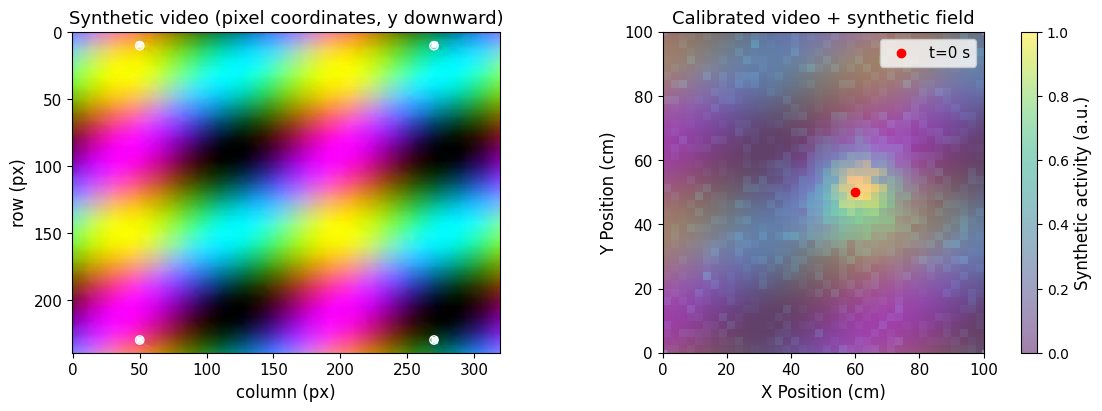

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].imshow(frame_0)
axes[0].scatter(
    landmarks_px[:, 0], landmarks_px[:, 1], facecolors="none", edgecolors="white"
)
axes[0].set_title("Synthetic video (pixel coordinates, y downward)")
axes[0].set_xlabel("column (px)")
axes[0].set_ylabel("row (px)")
# The exact landmarks yield a translated/flipped image extent in environment cm.
corners = calibration_landmarks.transform_px_to_cm(
    np.array([[0, video_height], [video_width, 0]])
)
axes[1].imshow(
    frame_0,
    extent=[corners[0, 0], corners[1, 0], corners[0, 1], corners[1, 1]],
    origin="upper",
    alpha=0.5,
)
env.plot_field(
    fields[0],
    ax=axes[1],
    alpha=0.5,
    vmin=0,
    vmax=1,
    colorbar_label="Synthetic activity (a.u.)",
)
axes[1].scatter(*trajectory[0], color="red", label="t=0 s")
axes[1].set_title("Calibrated video + synthetic field")
axes[1].set_aspect("equal")
axes[1].legend()
plt.show()

## Example 4: Creating VideoOverlay with Various Options

VideoOverlay supports several options for controlling appearance:

| Option | Description | Default |
|--------|-------------|----------|
| `alpha` | Opacity (0.0-1.0) | 0.5 |
| `z_order` | "above" or "below" field | "above" |
| `crop` | (x, y, width, height) | None |
| `downsample` | Spatial downsampling factor | 1 |
| `times` | Explicit source frame timestamps on the field clock | None (index alignment) |

In [11]:
print("Example 4a: Basic VideoOverlay")
print("=" * 50)

# Basic video overlay with calibration
video_overlay = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
)

print("VideoOverlay created:")
print(f"  source: {video_path.name}")
print(f"  alpha: {video_overlay.alpha} (default)")
print(f"  z_order: {video_overlay.z_order} (default)")

Example 4a: Basic VideoOverlay
VideoOverlay created:
  source: synthetic_video.mp4
  alpha: 0.5 (default)
  z_order: above (default)


In [12]:
print("\nExample 4b: Alpha Blending Options")
print("-" * 50)

# Field dominant (low alpha)
overlay_field_dominant = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
    alpha=0.3,  # 30% video, 70% field
)

# Balanced (default)
overlay_balanced = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
    alpha=0.5,  # 50% video, 50% field
)

# Video dominant (high alpha)
overlay_video_dominant = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
    alpha=0.7,  # 70% video, 30% field
)

print("Alpha options:")
print("  alpha=0.3: Field shows through video (field dominant)")
print("  alpha=0.5: Equal visibility (balanced, default)")
print("  alpha=0.7: Video shows through field (video dominant)")


Example 4b: Alpha Blending Options
--------------------------------------------------
Alpha options:
  alpha=0.3: Field shows through video (field dominant)
  alpha=0.5: Equal visibility (balanced, default)
  alpha=0.7: Video shows through field (video dominant)


In [13]:
print("\nExample 4c: Z-Order Options")
print("-" * 50)

# Video above field (default)
overlay_above = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
    z_order="above",  # Video on top of field
)

# Video below field (only visible if field has transparency)
overlay_below = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
    z_order="below",  # Video behind field
)

print("Z-order options:")
print("  z_order='above': Video on top (default, works with opaque fields)")
print("  z_order='below': Video behind (only visible if field has NaN/transparent)")


Example 4c: Z-Order Options
--------------------------------------------------
Z-order options:
  z_order='above': Video on top (default, works with opaque fields)
  z_order='below': Video behind (only visible if field has NaN/transparent)


In [14]:
print("\nExample 4d: Crop and Downsample")
print("-" * 50)

# Crop to region of interest
overlay_cropped = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
    crop=(50, 30, 200, 150),  # (x, y, width, height) in pixels
)

# Downsample for faster rendering
overlay_downsampled = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
    downsample=2,  # Half resolution (160x120)
)

print("Advanced options:")
print("  crop=(50, 30, 200, 150): Crop to 200x150 region starting at (50, 30)")
print("  downsample=2: Reduce resolution by factor of 2")


Example 4d: Crop and Downsample
--------------------------------------------------
Advanced options:
  crop=(50, 30, 200, 150): Crop to 200x150 region starting at (50, 30)
  downsample=2: Reduce resolution by factor of 2


## Example 5: Animating Fields with Video Background

Combine the spatial field animation with the video overlay using `animate_fields()`.

**Supported backends**:
- `napari`: Best for interactive exploration
- `video`: Best for exporting MP4 files
- `widget`: For Jupyter notebook playback
- `html`: NOT supported for VideoOverlay (warning emitted)

In [15]:
print("Example 5a: Napari Backend (Interactive)")
print("=" * 50)

# Create video overlay with position tracking
video_overlay = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
    alpha=0.5,
)

position_overlay = PositionOverlay(
    positions=trajectory,
    color="red",
    size=10.0,
    trail_length=10,
)

if RUN_NAPARI:
    try:
        import napari
        from IPython import get_ipython

        print("Launching Napari viewer...")

        # IMPORTANT: Clear cache before parallel rendering
        env.clear_cache()

        viewer = env.animate_fields(
            fields,
            overlays=[video_overlay, position_overlay],
            frame_times=frame_times,
            backend="napari",
            speed=1.0,
            title="Video + Field Animation",
        )

        print("\nNapari viewer opened:")
        print("  - Video layer with field overlay")
        print("  - Position tracking with trail")
        print("  - Use slider or play button to animate")

        if get_ipython() is None:
            napari.run()

    except ImportError:
        print("Napari not available. Install with: pip install 'napari[all]>=0.4.18'")
else:
    print("Optional viewer skipped; set RUN_NAPARI=True to enable it.")

Example 5a: Napari Backend (Interactive)
Optional viewer skipped; set RUN_NAPARI=True to enable it.


## Example 6: Exporting Synchronized Video

Export the animation with video overlay to an MP4 file.

**Key parameters**:
- `n_workers`: Number of parallel workers (speeds up rendering)
- `frame_times`: Output timing, one timestamp per field frame
- `dpi`: Output resolution

**Important**: Call `env.clear_cache()` before parallel rendering!

In [16]:
print("Example 6: Exporting Video with Overlay")
print("=" * 50)

if RUN_VIDEO_EXPORT and check_ffmpeg_available():
    output_path = output_dir / "18_video_overlay_export.mp4"

    # IMPORTANT: Clear cache before parallel rendering
    env.clear_cache()

    result = env.animate_fields(
        fields,
        overlays=[video_overlay, position_overlay],
        frame_times=frame_times,
        backend="video",
        save_path=output_path,
        speed=1.0,
        n_workers=1,  # script/notebook-safe; parallel export is a separate optimization
        dpi=100,
    )

    print(f"\nVideo exported to: {result}")
    print(f"  Frames: {n_frames}")
    print(f"  FPS: {video_fps}")
    print("  Workers: 1 (serial)")
else:
    print(
        "Video export disabled by default or ffmpeg unavailable (RUN_VIDEO_EXPORT=True)."
    )
    print("Install with: brew install ffmpeg (macOS) or apt install ffmpeg (Linux)")

Example 6: Exporting Video with Overlay
Video export disabled by default or ffmpeg unavailable (RUN_VIDEO_EXPORT=True).
Install with: brew install ffmpeg (macOS) or apt install ffmpeg (Linux)


In [17]:
print("Example 6b: Widget Backend (Jupyter Playback)")
print("-" * 50)

if RUN_WIDGET:
    try:
        from IPython import get_ipython
        from IPython.display import display

        if get_ipython() is not None:
            # Clear cache before rendering
            env.clear_cache()

            # Use only first 30 frames for quick demo
            n_demo = 30

            # Create video timestamps for the full video
            video_times = np.arange(n_video_frames) / video_fps
            # Create field timestamps for the demo subset
            field_times = video_times[:n_demo]

            widget = env.animate_fields(
                fields[:n_demo],
                overlays=[
                    VideoOverlay(
                        source=video_path,
                        calibration=calibration_landmarks,
                        times=video_times,  # Full video timestamps
                        alpha=0.5,
                    ),
                    PositionOverlay(
                        positions=trajectory[:n_demo],
                        color="red",
                        trail_length=10,
                    ),
                ],
                frame_times=field_times,  # Field timestamps for alignment
                backend="widget",
                speed=1.0,
            )
            print("Widget created - use slider to navigate")
            display(widget)
        else:
            print("Not in Jupyter notebook environment")

    except ImportError:
        print("IPython/ipywidgets not available")
else:
    print("Optional viewer skipped; set RUN_WIDGET=True to enable it.")

Example 6b: Widget Backend (Jupyter Playback)
--------------------------------------------------
Optional viewer skipped; set RUN_WIDGET=True to enable it.


## Example 7: Performance Tips for Large Videos

Behavioral videos can be 30+ minutes at 30fps = 50,000+ frames. Here's how to handle them efficiently:

### Memory Management

1. **LRU Caching**: VideoReader caches recently accessed frames (default: 100 frames)
2. **Streaming**: Frames are loaded on-demand, never all at once
3. **Downsampling**: Reduce resolution for faster rendering

### Rendering Optimization

1. **Parallel Export**: Use `n_workers > 1` for video export
2. **Subsampling**: Reduce frame count for preview
3. **Clear Cache**: Always call `env.clear_cache()` before parallel rendering

In [18]:
from neurospatial.animation import subsample_frames

print("Example 7: Performance Optimization")
print("=" * 50)

# Tip 1: Adjust cache size for your workflow
reader_small_cache = VideoReader(video_path, cache_size=50)
reader_large_cache = VideoReader(video_path, cache_size=200)

print("Tip 1: Adjust cache size")
print("  cache_size=50: Low memory, good for random access")
print("  cache_size=200: Higher memory, better for sequential playback")

# Tip 2: Downsample for faster rendering
print("\nTip 2: Downsample for speed")
overlay_fast = VideoOverlay(
    source=video_path,
    times=frame_times,
    calibration=calibration_landmarks,
    downsample=2,  # Half resolution
)
print(f"  Original: {video_width}x{video_height} pixels")
print(f"  Downsampled: {video_width // 2}x{video_height // 2} pixels")

# Tip 3: Subsample frames for preview
print("\nTip 3: Subsample frames for quick preview")
# Subsample from 30fps to 10fps
fields_subsampled = subsample_frames(fields, source_fps=30, target_fps=10)
print(f"  Original: {len(fields)} frames at 30fps")
print(f"  Subsampled: {len(fields_subsampled)} frames at 10fps")

Example 7: Performance Optimization
Tip 1: Adjust cache size
  cache_size=50: Low memory, good for random access
  cache_size=200: Higher memory, better for sequential playback

Tip 2: Downsample for speed
  Original: 320x240 pixels
  Downsampled: 160x120 pixels

Tip 3: Subsample frames for quick preview
  Original: 30 frames at 30fps
  Subsampled: 10 frames at 10fps


In [19]:
print("\nTip 4: CRITICAL - Clear cache before parallel rendering")
print("-" * 50)

# This is REQUIRED for parallel video export
env.clear_cache()

print("Always call env.clear_cache() before animate_fields() with n_workers > 1")
print("")
print("Why? The Environment object must be pickle-able for multiprocessing.")
print("Cached KDTree and kernel matrices cannot be pickled.")
print("")
print("Example:")
print("  env.clear_cache()  # Make environment pickle-able")
print(
    "  env.animate_fields(fields, frame_times=frame_times, overlays=[video], n_workers=4, ...)"
)


Tip 4: CRITICAL - Clear cache before parallel rendering
--------------------------------------------------
Always call env.clear_cache() before animate_fields() with n_workers > 1

Why? The Environment object must be pickle-able for multiprocessing.
Cached KDTree and kernel matrices cannot be pickled.

Example:
  env.clear_cache()  # Make environment pickle-able
  env.animate_fields(fields, frame_times=frame_times, overlays=[video], n_workers=4, ...)


## Cleanup

Release readers after optional viewers close. Temporary demo video is
retained for the lifetime of this notebook so an opted-in widget can still
request its frames. The operating system temp directory holds all artifacts.

In [20]:
reader.close()
reader_small_cache.close()
reader_large_cache.close()
print(
    f"Synthetic video and any opted-in export are in the temporary directory: {output_dir}"
)

Synthetic video and any opted-in export are in the temporary directory: /var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/neurospatial-example-18-exhmtsjt


## Key Takeaways

### Calibration Methods

1. **Scale Bar**: Use when you have a known-length reference in the video
   ```python
   calibration = calibrate_video(
       env, "video.mp4",
       scale_bar=((x1, y1), (x2, y2), length_cm)
   )
   ```

2. **Landmarks**: Use when you know pixel locations of arena corners
   ```python
   calibration = calibrate_video(
       env, "video.mp4",
       landmarks_px=corners_px,
       landmarks_env=corners_cm
   )
   ```

3. **Direct Scale**: Use when you know the exact cm/pixel ratio
   ```python
   calibration = calibrate_video(
       env, "video.mp4",
       cm_per_px=0.25
   )
   ```

### VideoOverlay Best Practices

| Goal | Settings |
|------|----------|
| Balanced view | `alpha=0.5, z_order="above"` (default) |
| Field dominant | `alpha=0.3, z_order="above"` |
| Video dominant | `alpha=0.7, z_order="above"` |
| Video background | `z_order="below"` (needs transparent field) |

### Backend Support

| Backend | VideoOverlay Support |
|---------|---------------------|
| Napari | Full support |
| Video | Full support |
| Widget | Full support |
| HTML | NOT supported (warning emitted) |

### Performance Checklist

- [ ] Call `env.clear_cache()` before parallel rendering
- [ ] Use `downsample=2` or higher for faster preview
- [ ] Use `subsample_frames()` to reduce frame count
- [ ] Adjust `cache_size` in VideoReader based on workflow

## Next Steps

- Apply VideoOverlay to your own behavioral recordings
- Combine with other overlays (Position, Bodypart, HeadDirection)
- Export publication-quality videos with synchronized behavior

For more details, see:
- [17: overlays](17_animation_with_overlays.ipynb) — other overlay types
- [16: animation](16_field_animation.ipynb) — backend choices